In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


# Smart MCQ Solver — Data Loading & EDA
Load train data and inspect basic structure before any preprocessing.

In [2]:
x_train=pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")

In [3]:
x_train.shape

(2000, 8)

In [4]:
x_train.head(3)

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C


#### Checking Null Values: 0 

In [5]:
x_train.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

#### Drop unused ID column

In [6]:
x_train=x_train.drop('id',axis=1)

## Duplicate Check
Checking duplicate prompts — kept intentionally (empirically improved leaderboard score vs. dropping them).

In [7]:
x_train.duplicated(subset='prompt').sum()

np.int64(242)

## Basic Feature Engineering: Length & Word Overlap
Prompt/option character lengths and prompt-option word overlap counts, used later for baseline heuristics and the ANN. Added directly to the entire train set as these features dont cause data leakage.

In [8]:
x_train['prompt_len']=x_train['prompt'].str.len()
for col in ['A','B','C','D','E']:
    x_train[f'{col}_len']=x_train[col].str.len()

def get_overlaps(row):
    prompt_words=set(row['prompt'].split())
    overlaps={}
    for col in ['A','B','C','D','E']:
        option_words=set(row[col].split())
        overlaps[f'{col}_overlap']=len(prompt_words & option_words)
    return pd.Series(overlaps)

overlaps_x_train=x_train.apply(get_overlaps,axis=1)
x_train=pd.concat([x_train,overlaps_x_train],axis=1)

## EDA: Answer Distribution
Checking class balance across A-E. Answers are slightly biased towards option B and least biased with option D.

Text(0.5, 1.0, 'Answer Distribution')

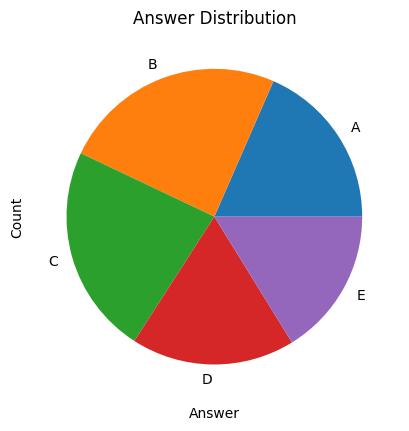

In [9]:
import matplotlib.pyplot as plt

answer=x_train['answer']
answer.value_counts().sort_index().plot(kind='pie')
plt.xlabel('Answer')
plt.ylabel('Count')
plt.title('Answer Distribution')

## EDA: Length Bias Check
Testing whether the correct answer is systematically the longest option.

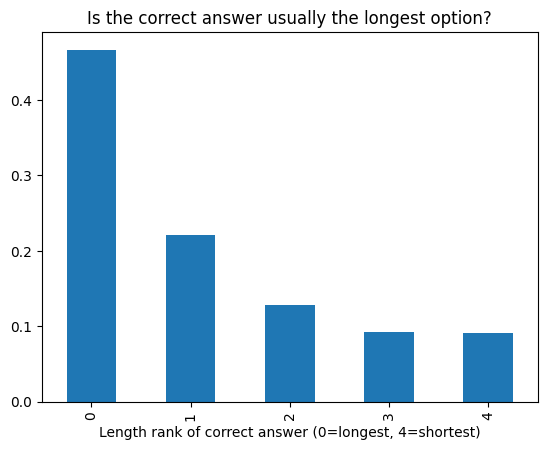

In [10]:
len_cols=['A_len','B_len','C_len','D_len','E_len']
lengths=x_train[len_cols].values
rank_of_correct=[]

for i,ans in enumerate(x_train['answer']):
    idx="ABCDE".index(ans)
    row_lengths=lengths[i]
    rank=(row_lengths > row_lengths[idx]).sum()
    rank_of_correct.append(rank)

pd.Series(rank_of_correct).value_counts(normalize=True).sort_index().plot(kind='bar')
plt.xlabel("Length rank of correct answer (0=longest, 4=shortest)")
plt.title("Is the correct answer usually the longest option?")
plt.show()

## EDA: Length Distributions
Sanity check on prompt/option length range — informs tokenizer max_length choice. So many of them have character length between 100 to 200. 

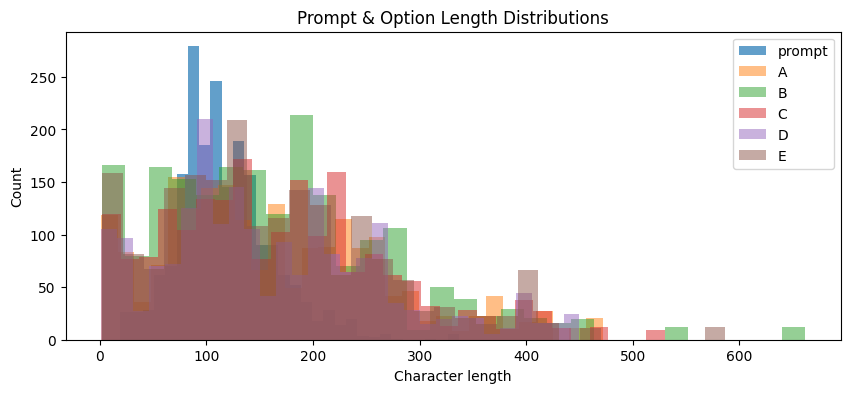

In [11]:
plt.figure(figsize=(10,4))
plt.hist(x_train['prompt_len'],bins=30,alpha=0.7,label='prompt')
for col in ['A','B','C','D','E']:
    plt.hist(x_train[f'{col}_len'],bins=30,alpha=0.5,label=col)
plt.xlabel('Character length')
plt.ylabel('Count')
plt.title('Prompt & Option Length Distributions')
plt.legend()
plt.show()

## EDA: Word Cloud
Most frequent terms across all prompts (stopwords + MCQ-boilerplate filtered out). Based on the common words, it is clear that the questions might be based on Science with predominant weightage to Physics followed by Biological Sciences.

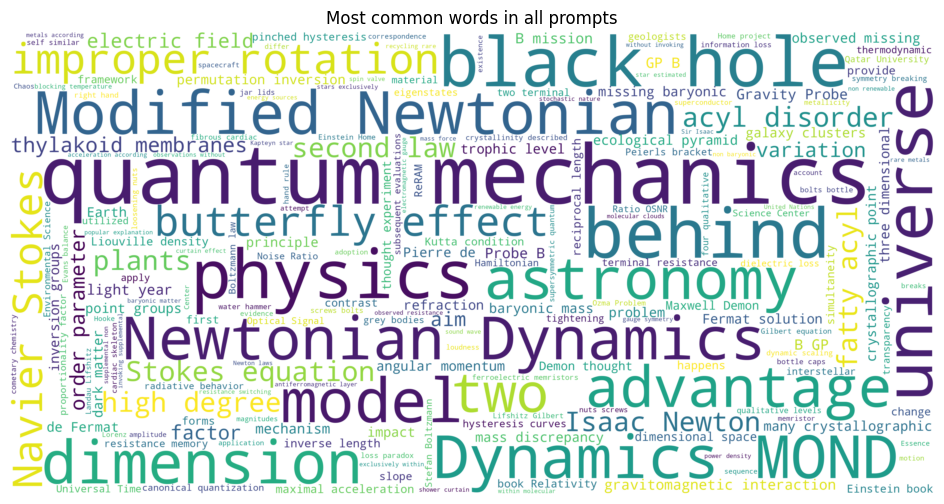

In [12]:
from wordcloud import WordCloud,STOPWORDS
import matplotlib.pyplot as plt

text=" ".join(x_train['prompt'].tolist())
custom_stopwords=[
    'following', 'listed', 'choices', 'choice', 'options', 'option',
    'correct', 'answer', 'answers', 'statement', 'statements',
    'identify', 'select', 'determine', 'pick', 'choose',
    'context', 'given', 'carefully', 'possible', 'best',
    'among', 'accurately', 'describes', 'describe', 'accurate',
    'based', 'relationship', 'role', 'reason', 'significance',
    'associated', 'used', 'term', 'distinction', 'defined', 'definition',
    'concept', 'measuring', 'origin', 'proposed', 'purpose',
    'focus', 'main', 'formation', 'processes'
]
wc=WordCloud(width=2000,height=1000,background_color='white',scale=2,stopwords=STOPWORDS.union(custom_stopwords),max_words=200).generate(text)

plt.figure(figsize=(12,6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Most common words in all prompts")
plt.show()

Separate Target Variable

In [13]:
answer=x_train['answer']
y_train=answer
x_train=x_train.drop('answer',axis=1)

### Helper Functions : MAP@3, Other Scores and Scores to Labels mapping

In [14]:
def score_to_labels(scores,top1=False):
    labels=[]
    top1_labels=[]
    for score in scores:
        scored=np.argsort(score)[::-1][:3]
        top_3=[chr(65+i) for i in scored]
        labels.append(" ".join(top_3))
        top1_labels.append(chr(65+np.argsort(score)[::-1][0]))
    if not top1:
        return labels
    else:
        return top1_labels

In [15]:
def map_at_3(predictions,ground_truth):
    ap_scores=[]
    for pred, truth in zip(predictions, ground_truth):
        pred_list = pred.split()
        if truth in pred_list:
            ap_scores.append(1.0 / (pred_list.index(truth) + 1))
        else:
            ap_scores.append(0.0)
    return sum(ap_scores) / len(ap_scores)

In [16]:
from sklearn.metrics import accuracy_score,f1_score

def support_metrics(train_scores,val_scores):
    train_acc=accuracy_score(score_to_labels(train_scores,top1=True),y_train)
    val_acc=accuracy_score(score_to_labels(val_scores,top1=True),y_val)
    train_f1=f1_score(score_to_labels(train_scores,top1=True),y_train,average='macro')
    val_f1=f1_score(score_to_labels(val_scores,top1=True),y_val,average='macro')
    return train_acc,val_acc,train_f1,val_f1

## Additional Features: Special-Option Flags & Length Rank
Flagging "none/all of the above"-style options, and ranking options by length per row.

In [17]:
def special_option(text):
    text=str(text).lower()
    patterns=['none of the above','all of the above','none of these','all of these','both a and b','both a and c','both b and c','not applicable']
    return int(any(p in text for p in patterns))

In [18]:
for col in ['A','B','C','D','E']:
    x_train[f'{col}_is_special']=x_train[col].apply(special_option)
x_train.head(12)

,prompt,A,B,C,D,E,prompt_len,A_len,B_len,C_len,...,A_overlap,B_overlap,C_overlap,D_overlap,E_overlap,A_is_special,B_is_special,C_is_special,D_is_special,E_is_special
0,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,142,307,258,222,...,6,5,8,8,5,0,0,0,0,0
1,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,43,406,364,365,...,2,2,2,2,2,0,0,0,0,0
2,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,182,12,11,9,...,0,0,0,0,0,0,0,0,0,0
3,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,129,307,258,222,...,6,5,8,8,5,0,0,0,0,0
4,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,110,230,233,233,...,3,3,3,2,2,0,0,0,0,0
5,Identify the correct statement: What is the ef...,"An electric field, precisely aligned with the ...","A magnetic field, randomly aligned with the sp...","A magnetic field, precisely aligned with the s...","A gravitational field, randomly aligned with t...","A gravitational field, precisely aligned with ...",116,56,54,55,...,1,1,1,1,1,0,0,0,0,0
6,"Which of the following is correct? What is a ""...",A type of coffee that is made by boiling coffe...,A pattern left by a particle-laden liquid afte...,A type of coffee that is made by mixing instan...,A type of coffee that is made by pouring hot w...,A pattern left by a particle-laden liquid afte...,96,65,163,70,...,3,4,2,4,3,0,0,0,0,0
7,Select the most accurate option: What is the L...,The Liouville density is a probability distrib...,The Liouville density is a quasiprobability di...,The Liouville density is a bounded probability...,The Liouville density is a probability distrib...,The Liouville density is a probability distrib...,89,172,141,126,...,3,3,2,2,3,0,0,0,0,0
8,Select the most accurate option: What are the ...,"They are unknown, but possibilities include la...",They are known to be black holes and Preon stars.,They are only MACHOs.,They are clusters of brown dwarfs.,They are new particles such as RAMBOs.,79,112,49,21,...,1,1,1,2,1,0,0,0,0,0
9,Which of the following is correct? What is the...,"The Wigner function W(x, p) is the Wigner tran...","The Wigner function W(x, p) is a source functi...","The Wigner function W(x, p) is the derivative ...","The Wigner function W(x, p) represents the Ham...","The Wigner function W(x, p) is the time deriva...",148,240,174,123,...,8,8,7,6,7,0,0,0,0,0


In [19]:
def length_rank_features(row):
    option_cols=['A','B','C','D','E']
    lengths={col:row[f'{col}_len'] for col in option_cols}
    sorted_options=sorted(option_cols,key=lambda col:lengths[col],reverse=True)
    ranks={}
    for rank,col in enumerate(sorted_options):
        ranks[f'{col}_len_rank']=rank
    return pd.Series(ranks)

rank_df_train=x_train.apply(length_rank_features,axis=1)
x_train=pd.concat([x_train,rank_df_train],axis=1)

## Experiment Tracking Setup (W&B)

In [20]:
!pip install wandb -q

In [21]:
import wandb
from kaggle_secrets import UserSecretsClient
import os

secrets=UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login()
wandb_mode=False

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


# Baseline 1: Longest-Option Heuristic
Naive baseline — always guess the longest option first.

In [22]:
def len_scores(row):
    lengths=[row['A_len'],row['B_len'],row['C_len'],row['D_len'],row['E_len']]
    max_len=max(lengths)
    min_len=min(lengths)
    scores=[]
    for length in lengths:
        score=0
        if length==max_len:
            score=0.5
        elif length==min_len:
            score=0.2
        else:
            score=0.3
        scores.append(score)
    return scores

length_train_scores=x_train.apply(len_scores,axis=1).to_list()
length_labels=score_to_labels(length_train_scores)
length_map3=map_at_3(length_labels,y_train)
print(length_map3)

0.525


In [23]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="largestlen-baseline-metrics",id="largelen_v1",resume="allow")
    wandb.log({
        "map_at_3_train":length_map3,   
        "map_at_3_val":length_val_map3,
        "accuracy_at_train":len_train_acc,
        "accuracy_at_val":len_val_acc,
        "f1_at_train":len_train_f1,
        "f1_at_val":len_val_f1,
        "metric":"Longest-Length"
        })
    wandb.finish()

# Baseline 2: TF-IDF Similarity
Scoring each option by prompt-option TF-IDF overlap.

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf=TfidfVectorizer(sublinear_tf=True,ngram_range=(1,2))
all_text=x_train['prompt'].tolist()+x_train['A'].tolist()+x_train['B'].tolist()+x_train['C'].tolist()+x_train['D'].tolist()+x_train['E'].tolist()
tfidf.fit(all_text)

TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

In [25]:
tfidf_train_scores=[]
for col in ['A', 'B', 'C', 'D', 'E']:
    combined=(x_train['prompt']+" "+x_train[col]).to_list()
    scores=tfidf.transform(combined).sum(axis=1)
    tfidf_train_scores.append(np.asarray(scores).flatten())
tfidf_train_scores=np.array(tfidf_train_scores).T

In [26]:
tfidf_train_labels=score_to_labels(tfidf_train_scores,top1=False)
tfidf_train_map3=map_at_3(tfidf_train_labels,y_train)
print(tfidf_train_map3)

0.5401666666666667


In [27]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="tfidf-baseline-metrics",id="tfidf_v1",resume="allow")
    wandb.log({
        "map_at_3_train":tfidf_train_map3,   
        "map_at_3_val":tfidf_val_map3,
        "accuracy_at_train":tfidf_train_acc,
        "accuracy_at_val":tfidf_val_acc,
        "f1_at_train":tfidf_train_f1,
        "f1_at_val":tfidf_val_f1,
        "vectorizer":"TfidfVectorizer",
        "sublinear_tf":True})
    wandb.finish()

In [28]:
import torch
import numpy as np
import random

seed=42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

# Baseline 3 : Word2Vec Embeddings
Training a lightweight Word2Vec model on train text for prompt-option cosine similarity scoring, feeding into the ANN's input features.

In [29]:
from gensim.models import Word2Vec
np.random.seed(1)
from numpy.random import seed
seed(1)

sentences=[text.split() for text in all_text]
word2vec=Word2Vec(sentences,vector_size=10,window=1,min_count=1,seed=1,workers=1,epochs=10)

In [30]:
option_cols=['A','B','C','D','E']
def sentence_embedding(text):
    words=text.split()
    embedding=[word2vec.wv[word] for word in words if word in word2vec.wv]
    if len(embedding)==0:
        return np.zeros(word2vec.vector_size)
    return np.mean(embedding,axis=0)

In [31]:
prompts=np.vstack(x_train['prompt'].apply(sentence_embedding))
w2v_train_scores=[]

for col in option_cols:
    option_matrix=np.vstack(x_train[col].apply(sentence_embedding))
    scores=np.diag(cosine_similarity(prompts,option_matrix))
    w2v_train_scores.append(scores)
w2v_train_scores=np.array(w2v_train_scores).T

In [32]:
prompts=np.vstack(x_train['prompt'].apply(sentence_embedding))
w2v_train_scores=[]

for col in option_cols:
    option_matrix=np.vstack(x_train[col].apply(sentence_embedding))
    scores=np.diag(cosine_similarity(prompts,option_matrix))
    w2v_train_scores.append(scores)
w2v_train_scores=np.array(w2v_train_scores).T

In [33]:
w2v_train_labels=score_to_labels(w2v_train_scores)
w2v_train_map3=map_at_3(w2v_train_labels,y_train)
print(w2v_train_map3)

0.371


In [34]:
#w2v_train_acc,w2v_val_acc,w2v_train_f1,w2v_val_f1=support_metrics(w2v_train_scores,w2v_val_scores)

if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="word2vec-baseline-metrics",id="w2v_v1", resume="allow")
    wandb.log({
        "map_at_3_train":w2v_train_map3,   
        "map_at_3_val":w2v_val_map3,
        "accuracy_at_train":w2v_train_acc,
        "accuracy_at_val":w2v_val_acc,
        "f1_at_train":w2v_train_f1,
        "f1_at_val":w2v_val_f1,
        "embedding_model":"Word2Vec",
        "vector_size":20,
         "window":1,
         "min_count":1})
    wandb.finish()

In [35]:
cols=x_train.columns
cols=cols.drop(['prompt',"A","B","C","D",'E'])

In [36]:
len(cols)

21

#### Label Encoding

In [37]:
label_map={"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}

y_train_idx=y_train.map(label_map).values if y_train.dtype=='object' else y_train.values

In [38]:
from torch.utils.data import TensorDataset,DataLoader
from sklearn.preprocessing import StandardScaler

ss=StandardScaler()

x_train_t=torch.tensor(ss.fit_transform(np.concatenate((tfidf_train_scores,np.array(length_train_scores),w2v_train_scores,x_train[cols].values),axis=1)),dtype=torch.float32)
y_train_t=torch.tensor(y_train_idx,dtype=torch.long)

# Baseline 4 (MODEL 1): Custom ANN (MCQANN)
Small feed-forward network over TF-IDF + length + Word2Vec + other engineered features.

In [39]:
from torch.utils.data import TensorDataset,DataLoader

train_ds=TensorDataset(x_train_t,y_train_t)
train_loader=DataLoader(train_ds,batch_size=16,shuffle=True)

In [40]:
import torch.nn as nn

class MCQANN(nn.Module):
    def __init__(self,input_dim,num_choices=5,hidden_dim=32):
        super().__init__()
        self.net=nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim,hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim//2,num_choices)
        )
    def forward(self,x):
        return self.net(x)

model=MCQANN(input_dim=x_train_t.shape[1])

In [41]:
wandb.init(project="24f2002314-t22026",name="MCQ-ANN-scaled",id="ann_version_scaled2",resume="allow")
wandb.log({
        "lr":3e-4,   
        "weight_decay":1e-4,
        "epochs": 400,
        "patience": 15,
        "hidden_dimension":16,
        "batch_size": 32,
        "architecture": "MCQANN",
        "input_dim": x_train_t.shape[1],})

wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260731_181117-ann_version_scaled2
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run MCQ-ANN-scaled
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/ann_version_scaled2


In [42]:
import copy

criteria=nn.CrossEntropyLoss()
EPOCHS=400
optimizer=torch.optim.Adam(model.parameters(),lr=3e-4,weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=1e-6)
device="cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

best_train_loss=float('inf')
patience=15
patience_count=0
best_train_map3=0
for epoch in range(EPOCHS):
    model.train()
    total_loss=0
    for x,y in train_loader:
        x,y=x.to(device),y.to(device)
        optimizer.zero_grad()
        output=model(x)
        loss=criteria(output,y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
        optimizer.step()
        total_loss+=loss.item()
    scheduler.step()

    avg_train_loss=total_loss/len(train_loader)
    print(f'Epoch :{epoch} - train loss : {avg_train_loss:.4f}')
    wandb.log({
        "epoch": epoch,
        "train_loss": avg_train_loss,
    })

    if avg_train_loss<=best_train_loss-1e-4:
        best_train_loss=avg_train_loss
        patience_count=0
        best_state=copy.deepcopy(model.state_dict())
    else:
        patience_count+=1
        if patience_count>=patience:
            print(f"Early stopping at epoch {epoch}")
            break

model.load_state_dict(best_state)

Epoch :0 - train loss : 1.6237
Epoch :1 - train loss : 1.5827
Epoch :2 - train loss : 1.5494
Epoch :3 - train loss : 1.5065
Epoch :4 - train loss : 1.4739
Epoch :5 - train loss : 1.4600
Epoch :6 - train loss : 1.4115
Epoch :7 - train loss : 1.3933
Epoch :8 - train loss : 1.3801
Epoch :9 - train loss : 1.3665
Epoch :10 - train loss : 1.3413
Epoch :11 - train loss : 1.3424
Epoch :12 - train loss : 1.3078
Epoch :13 - train loss : 1.2949
Epoch :14 - train loss : 1.2775
Epoch :15 - train loss : 1.2509
Epoch :16 - train loss : 1.2417
Epoch :17 - train loss : 1.2313
Epoch :18 - train loss : 1.2522
Epoch :19 - train loss : 1.2121
Epoch :20 - train loss : 1.2007
Epoch :21 - train loss : 1.2006
Epoch :22 - train loss : 1.2003
Epoch :23 - train loss : 1.1632
Epoch :24 - train loss : 1.1693
Epoch :25 - train loss : 1.1785
Epoch :26 - train loss : 1.1521
Epoch :27 - train loss : 1.1404
Epoch :28 - train loss : 1.1174
Epoch :29 - train loss : 1.1201
Epoch :30 - train loss : 1.1174
Epoch :31 - train 

<All keys matched successfully>

In [43]:
device='cuda' if torch.cuda.is_available() else 'cpu'
model.eval()
with torch.no_grad():
    predictions=model(x_train_t.to(device)).argmax(dim=1).cpu().numpy()
    targets=y_train_t.to(device).cpu().numpy()

accuracy_ann=accuracy_score(targets,predictions)
print(f"Accuracy: {accuracy_ann}")

Accuracy: 0.928


In [44]:
"""wandb.run.summary["best_val_loss"]=best_val_loss.item()
wandb.run.summary["best_val_map3"]=val_map3   
wandb.run.summary["stopped_epoch"]=epoch
torch.save(best_state,"best_model.pt")
artifact=wandb.Artifact("mcq_ann_best_model",type="model")
artifact.add_file("best_model.pt")
wandb.log_artifact(artifact)
wandb.finish()"""

'wandb.run.summary["best_val_loss"]=best_val_loss.item()\nwandb.run.summary["best_val_map3"]=val_map3   \nwandb.run.summary["stopped_epoch"]=epoch\ntorch.save(best_state,"best_model.pt")\nartifact=wandb.Artifact("mcq_ann_best_model",type="model")\nartifact.add_file("best_model.pt")\nwandb.log_artifact(artifact)\nwandb.finish()'

### Building the dataset

In [45]:
from datasets import Dataset

label_map={'A':0,'B':1,'C':2,'D':3,'E':4}

x_train['label']=y_train.map(label_map)
train_dataset=Dataset.from_pandas(x_train.reset_index(drop=True))

### Helper Function for Option Augmentation/Shuffling

In [46]:
import random

def shuffle_option(row):
    cols=['A','B','C','D','E']
    correct_idx=row['label']
    correct_ans=row[cols[correct_idx]]
    values=[row[c] for c in cols]
    random.shuffle(values)
    new=values.index(correct_ans)
    for i,c in enumerate(cols):
        row[c]=values[i]
    row['label']=new
    return row

In [47]:
train_dataset=train_dataset.map(shuffle_option)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

# Transformer Fine-Tuning (Pretrained Models 2 and 3: Electra & RoBERTa)
Multiple-choice fine-tuning on the augmented training set (duplicates kept, options shuffled/relabeled). This is the core model for final predictions.

In [48]:
from transformers import AutoModelForMultipleChoice,AutoTokenizer,TrainingArguments,Trainer
import torch

model_name1='google/electra-base-discriminator'
tokeniser1=AutoTokenizer.from_pretrained(model_name1)
model1=AutoModelForMultipleChoice.from_pretrained(model_name1,ignore_mismatched_sizes=True)

model_name2='roberta-base'
tokeniser2=AutoTokenizer.from_pretrained(model_name2)
model2=AutoModelForMultipleChoice.from_pretrained(model_name2,ignore_mismatched_sizes=True)

def preprocessing(data,tokeniser):
    prompts=[[p]*5 for p in data['prompt']]
    options=[[data[o][i] for o in ['A','B','C','D','E']] for i in range(len(data['prompt']))]
    prompts=sum(prompts,[])
    options=sum(options,[])
    processed=tokeniser(prompts,options,truncation=True,max_length=256,padding='max_length')
    result={k:[v[i:i+5] for i in range(0,len(v),5)] for k,v in processed.items()}
    if "label" in data:
         result["label"]=data["label"]

    return result

processed_train1=train_dataset.map(lambda x:preprocessing(x,tokeniser1),batched=True,remove_columns=train_dataset.column_names)
processed_train2=train_dataset.map(lambda x:preprocessing(x,tokeniser2),batched=True,remove_columns=train_dataset.column_names)

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

... (8 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForMultipleChoice LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.pooler.dense.weight     | MISSING    | 
classifier.weight               | MISSING    | 
classifier.bias                 | MISSING    | 
roberta.pooler.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [49]:
from sklearn.metrics import f1_score

def compute_metrics(eval_pred):
    logits,labels=eval_pred
    top3=np.argsort(-logits,axis=1)[:,:3]
    ap=[1.0/(list(row).index(l)+1) if l in row else 0.0 for row,l in zip(top3,labels)]
    acc=(np.argmax(logits, axis=1)==labels).mean()
    preds=np.argmax(logits,axis=1)
    f1_macro=f1_score(labels,preds,average="macro")
    return {"map_at_3":np.mean(ap),"accuracy":acc,"f1_macro":f1_macro}

### Training Loop

In [50]:
from transformers import set_seed
SEED=42
set_seed(SEED)

In [51]:
processed_train1.set_format(type="torch",columns=["input_ids","attention_mask","label"])

train_args1=TrainingArguments(output_dir="./electra-base-mcq",learning_rate=4e-5,eval_strategy="steps",eval_steps=150,gradient_checkpointing=False,save_strategy="no",num_train_epochs=6,warmup_steps=100,remove_unused_columns=False,max_grad_norm=1.0,
                             fp16=True,weight_decay=0.01,logging_steps=50,per_device_train_batch_size=8,per_device_eval_batch_size=8,load_best_model_at_end=False)

trainer1=Trainer(model=model1,args=train_args1,train_dataset=processed_train1,compute_metrics=compute_metrics,eval_dataset=processed_train1,)
trainer1.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss,Validation Loss,Map At 3,Accuracy,F1 Macro
150,1.543263,1.424469,0.931417,0.905000,0.904973
300,0.110152,0.039612,0.996417,0.994500,0.994460
450,0.030493,0.007785,1.000000,1.000000,1.000000
600,0.001880,0.000040,1.000000,1.000000,1.000000
750,0.000301,0.000021,1.000000,1.000000,1.000000


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

TrainOutput(global_step=750, training_loss=0.6057784119496743, metrics={'train_runtime': 1769.6018, 'train_samples_per_second': 6.781, 'train_steps_per_second': 0.424, 'total_flos': 7893260789760000.0, 'train_loss': 0.6057784119496743, 'epoch': 6.0})

In [52]:
processed_train2.set_format(type="torch",columns=["input_ids","attention_mask","label"])

train_args2=TrainingArguments(output_dir="./roberta-base-mcq",learning_rate=4e-5,eval_strategy="steps",eval_steps=150,gradient_checkpointing=False,save_strategy="no",num_train_epochs=6,warmup_steps=100,remove_unused_columns=False,max_grad_norm=1.0,
                             fp16=True,weight_decay=0.01,logging_steps=10,per_device_train_batch_size=8,per_device_eval_batch_size=8,load_best_model_at_end=False)

trainer2=Trainer(model=model2,args=train_args2,train_dataset=processed_train2,compute_metrics=compute_metrics,eval_dataset=processed_train1,)
trainer2.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss,Validation Loss,Map At 3,Accuracy,F1 Macro
150,1.361766,3.177068,0.431333,0.270500,0.270297
300,0.163225,3.191921,0.490583,0.331500,0.331305
450,0.057264,3.921882,0.427333,0.247500,0.247147
600,0.007016,3.742482,0.435083,0.249000,0.248780
750,0.000066,3.622410,0.443333,0.258500,0.258292


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

TrainOutput(global_step=750, training_loss=0.6165202379718734, metrics={'train_runtime': 1780.8191, 'train_samples_per_second': 6.738, 'train_steps_per_second': 0.421, 'total_flos': 7893260789760000.0, 'train_loss': 0.6165202379718734, 'epoch': 6.0})

In [53]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="electra-final",id="electra-base-final",resume="allow")
    wandb.log({   
        "metrics":val_results1.metrics,
        "MODEL":"ELECTRA-BASE-DISCRIMINATOR",
        "epochs":6,
        "learning_rate":4e-5,
        "warm-up":500,
        "weight_decay":0.01
         })
    wandb.finish()

In [54]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="roberta-final",id="roberta-base-final",resume="allow")
    wandb.log({   
        "metrics":val_results2.metrics,
        "MODEL":"ROBERTA-BASE",
        "epochs":5,
        "learning_rate":3e-5,
        "warm-up":500,
        "weight_decay":0.01
         })
    wandb.finish()

## Obtained Results on Various Baselines

In [55]:
"""comparison = pd.DataFrame({
    'Model': ['Longest-Length', 'TF-IDF', 'Word2Vec', 'Custom ANN', 'Electra-base','Roberta-base'],
    'Val MAP@3': [length_val_map3, tfidf_val_map3, w2v_val_map3, best_val_map3, 
                  val_results1.metrics['test_map_at_3'],val_results2.metrics['test_map_at_3']],
    'Val Accuracy': [len_val_acc, tfidf_val_acc, w2v_val_acc,accuracy_ann,
                     val_results1.metrics['test_accuracy'],val_results2.metrics['test_accuracy']]
})
comparison"""

"comparison = pd.DataFrame({\n    'Model': ['Longest-Length', 'TF-IDF', 'Word2Vec', 'Custom ANN', 'Electra-base','Roberta-base'],\n    'Val MAP@3': [length_val_map3, tfidf_val_map3, w2v_val_map3, best_val_map3, \n                  val_results1.metrics['test_map_at_3'],val_results2.metrics['test_map_at_3']],\n    'Val Accuracy': [len_val_acc, tfidf_val_acc, w2v_val_acc,accuracy_ann,\n                     val_results1.metrics['test_accuracy'],val_results2.metrics['test_accuracy']]\n})\ncomparison"

## Test Dataset Preprocessing and creating inference of the Selected Model - Electra Base

In [56]:
test=pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
test['prompt_len']=test['prompt'].str.len()
for col in ['A','B','C','D','E']:
    test[f'{col}_len']=test[col].str.len()

def get_overlaps(row):
    prompt_words=set(row['prompt'].split())
    overlaps={}
    for col in ['A','B','C','D','E']:
        option_words=set(row[col].split())
        overlaps[f'{col}_overlap']=len(prompt_words & option_words)
    return pd.Series(overlaps)

overlaps_test=test.apply(get_overlaps,axis=1)
test=pd.concat([test,overlaps_test],axis=1)

test_dataset=Dataset.from_pandas(test)
processed_test1=test_dataset.map(lambda x:preprocessing(x,tokeniser1),batched=True,remove_columns=test_dataset.column_names)
processed_test2=test_dataset.map(lambda x:preprocessing(x,tokeniser2),batched=True,remove_columns=test_dataset.column_names)

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [57]:
test_results1=trainer1.predict(processed_test1)
logits1=test_results1.predictions
letters=np.array(["A","B","C","D","E"])
top3=np.argsort(logits1,axis=1)[:, ::-1][:, :3]
top3=[" ".join(letters[row]) for row in top3]
print(top3[:10])

['A C D', 'B E D', 'B A C', 'E C B', 'C A D', 'D B E', 'E D A', 'B C A', 'C E D', 'B E C']


In [58]:
submission=pd.DataFrame({'id':test['id'],'Prediction':top3})
submission.to_csv('submission.csv',index=False)
print("Model submission saved!")
print(submission.head())

Model submission saved!
   id Prediction
0   1      A C D
1   2      B E D
2   3      B A C
3   4      E C B
4   5      C A D
